<a href="https://colab.research.google.com/github/tofighi/tutorials/blob/master/ML/Module_2_End_to_End_Machine_Learning_Pipelines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 2: End-to-End Machine Learning Pipelines

Welcome to **Module 2**! In this unified module, we combine the key concepts of **Classification** and **Regression** into a cohesive end-to-end Machine Learning pipeline.

---

## 🎯 Learning Objectives
By the end of this module, you will be able to:
1. Perform numerical and visual **Exploratory Data Analysis (EDA)**.
2. Handle categorical attributes using **One-Hot Encoding**.
3. Understand the distinction between **Model Parameters** and **Hyperparameters**.
4. Train and evaluate **Classification Models** ($k$-NN, Logistic Regression, Decision Trees) and **Regression Models** (Linear Regression, Ridge, Lasso).
5. Apply **Train/Test Splitting** and **Cross-Validation** to evaluate generalization performance.
6. Perform **Hyperparameter Tuning** using `GridSearchCV`.
7. Build clean, leak-free pipelines using `scikit-learn`'s `Pipeline` and `StandardScaler`.


---
# Part A: Classification Pipeline (Iris Dataset)

In this section, we walk through a complete classification pipeline using the classic Iris dataset to classify iris flowers into species.


### A1. Data Loading & Preprocessing


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load dataset directly from UCI repository
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'
df_iris = pd.read_csv(url, names=["sl", "sw", "pl", "pw", "target"], header=None)

# Convert target column to categorical data type
df_iris['target'] = df_iris['target'].astype('category')
df_iris.head()


,sl,sw,pl,pw,target
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### A2. Exploratory Data Analysis (EDA)


In [2]:
print("--- Dataset Information ---")
df_iris.info()

print("\n--- Feature Statistics ---")
df_iris.describe()


--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   sl      150 non-null    float64 
 1   sw      150 non-null    float64 
 2   pl      150 non-null    float64 
 3   pw      150 non-null    float64 
 4   target  150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB

--- Feature Statistics ---


,sl,sw,pl,pw
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


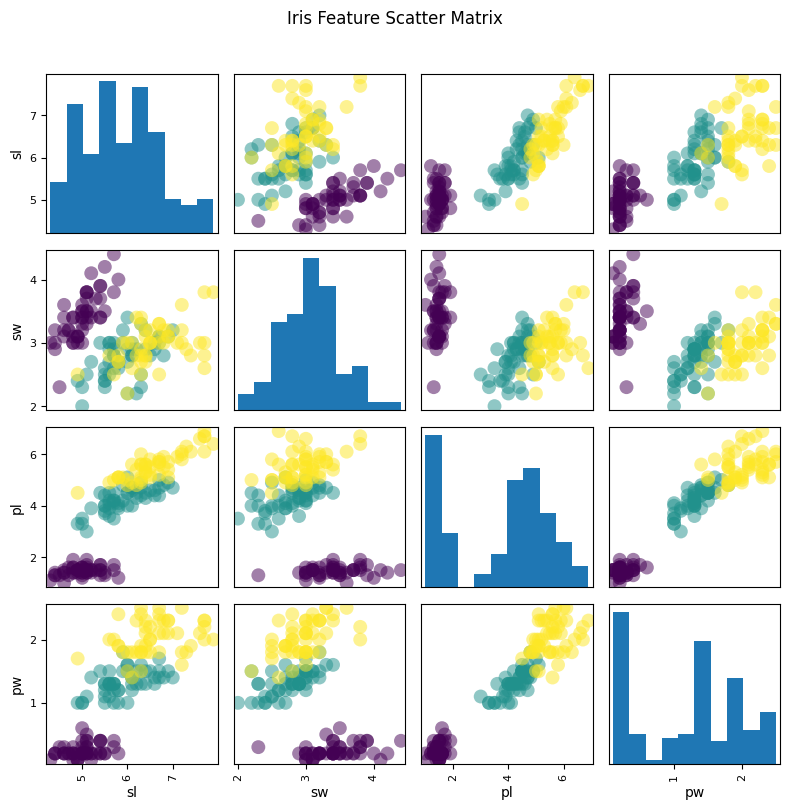

In [3]:
# Pairwise scatter matrix colored by target class
pd.plotting.scatter_matrix(df_iris, c=df_iris['target'].cat.codes, figsize=(8, 8), s=100, marker='o', cmap='viridis')
plt.suptitle('Iris Feature Scatter Matrix', y=1.02)
plt.tight_layout()
plt.show()


### A3. Handling Categorical Features (One-Hot Encoding)
ML algorithms strictly require numerical input features. When dealing with categorical non-ordinal variables, we use **One-Hot Encoding** (`pd.get_dummies` with `drop_first=True`) to avoid multicollinearity (the dummy variable trap).


In [4]:
# Demonstration of One-Hot Encoding on categorical data
demo_df = pd.DataFrame({'color': ['red', 'blue', 'green', 'blue', 'red'], 'price': [10, 20, 15, 20, 10]})
encoded_df = pd.get_dummies(demo_df, columns=['color'], drop_first=True)
encoded_df


,price,color_green,color_red
0,10,False,True
1,20,False,False
2,15,True,False
3,20,False,False
4,10,False,True


### A4. Feature Matrix ($X$) & Target Vector ($y$) Split


In [5]:
X_iris = df_iris[["sl", "sw", "pl", "pw"]]
y_iris = df_iris['target']

print(f"Feature matrix X shape: {X_iris.shape}")
print(f"Target vector y shape:  {y_iris.shape}")


Feature matrix X shape: (150, 4)
Target vector y shape:  (150,)


### A5. Train/Test Split & Model Evaluation
To evaluate model performance on unseen data, we split data into **Training** (80%) and **Test** (20%) sets.


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 80-20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X_iris, y_iris, test_size=0.20, random_state=42)

# Train k-NN Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Predict on test set
y_pred = knn.predict(X_test)

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Test Accuracy: 1.0000

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



### A6. Hyperparameter Tuning using `GridSearchCV`
- **Model Parameters**: Internal parameters learned from data during training (e.g., weights, coefficients).
- **Hyperparameters**: External configurations set manually before training (e.g., $k$ in $k$-NN, regularization $\lambda$).

We systematically tune hyperparameters using **$k$-Fold Cross Validation** via `GridSearchCV`.


In [7]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# 1. k-NN Tuning
knn_grid = GridSearchCV(KNeighborsClassifier(), {'n_neighbors': [3, 5, 7, 9, 11]}, cv=5)
knn_grid.fit(X_iris, y_iris)
print(f"Best k-NN Params: {knn_grid.best_params_} | Best CV Accuracy: {knn_grid.best_score_:.4f}")

# 2. Logistic Regression Tuning
lr_grid = GridSearchCV(LogisticRegression(solver='saga', max_iter=10000), {'penalty': ['l1', 'l2']}, cv=5)
lr_grid.fit(X_iris, y_iris)
print(f"Best LogReg Params: {lr_grid.best_params_} | Best CV Accuracy: {lr_grid.best_score_:.4f}")

# 3. Decision Tree Tuning
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=42), {'criterion': ['gini', 'entropy'], 'max_depth': range(2, 10)}, cv=5)
dt_grid.fit(X_iris, y_iris)
print(f"Best Tree Params:   {dt_grid.best_params_} | Best CV Accuracy: {dt_grid.best_score_:.4f}")


Best k-NN Params: {'n_neighbors': 7} | Best CV Accuracy: 0.9800
Best LogReg Params: {'penalty': 'l2'} | Best CV Accuracy: 0.9733
Best Tree Params:   {'criterion': 'gini', 'max_depth': 3} | Best CV Accuracy: 0.9733


---
# Part B: Regression Pipeline (Gapminder Dataset)

In this section, we build a regression pipeline to predict continuous targets (Country Life Expectancy) from socio-economic indicators.


### B1. Building Blocks of Linear Regression
1. **Hypothesis**: $\hat{y} = \theta_0 + \theta_1 x_1 + \dots + \theta_n x_n$
2. **Cost Function (MSE)**: $J(\theta) = \frac{1}{2m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})^2$
3. **Evaluation Metrics**:
   - **$R^2$ Score**: Proportion of variance explained ($1.0$ is perfect score).
   - **Mean Absolute Error (MAE)**: Average absolute magnitude of errors $\frac{1}{m}\sum |y - \hat{y}|$.
   - **Root Mean Squared Error (RMSE)**: Square root of MSE $\sqrt{\frac{1}{m}\sum (y - \hat{y})^2}$, expressed in same target units.


### B2. Data Loading & Feature Selection


In [8]:
url_gap = 'https://raw.githubusercontent.com/tofighi/MachineLearning/master/datasets/gapminder.csv'
df_gap = pd.read_csv(url_gap)

# Drop categorical 'Region' column for initial numeric regression
df_gap_num = df_gap.drop('Region', axis=1)

X_gap = df_gap_num.drop('life', axis=1)
y_gap = df_gap_num['life']

X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(X_gap, y_gap, test_size=0.30, random_state=42)
print(f"Train features shape: {X_train_g.shape} | Test features shape: {X_test_g.shape}")


Train features shape: (97, 8) | Test features shape: (42, 8)


### B3. Model Fitting & Performance Metrics


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

reg = LinearRegression()
reg.fit(X_train_g, y_train_g)
y_pred_g = reg.predict(X_test_g)

print("--- Multiple Linear Regression Performance ---")
print(f"R² Score: {r2_score(y_test_g, y_pred_g):.4f}")
print(f"MAE:      {mean_absolute_error(y_test_g, y_pred_g):.4f}")
print(f"RMSE:     {np.sqrt(mean_squared_error(y_test_g, y_pred_g)):.4f}")


--- Multiple Linear Regression Performance ---
R² Score: 0.8380
MAE:      2.3625
RMSE:     3.2476


### B4. Cross-Validation & Regularization (Ridge & Lasso)
To prevent overfitting when features are correlated or high-dimensional:
- **Ridge ($L_2$) Penalty**: Adds $\lambda \sum w_j^2$ to the loss function. Shrinks coefficients towards zero.
- **Lasso ($L_1$) Penalty**: Adds $\lambda \sum |w_j|$ to the loss function. Drives non-important coefficients to **exactly zero** (Feature Selection).


In [10]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score

# 1. Cross Validation Score on Linear Regression
cv_scores = cross_val_score(LinearRegression(), X_gap, y_gap, cv=5, scoring='r2')
print(f"5-Fold CV Mean R²: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

# 2. Ridge Regression Hyperparameter Tuning
alpha_space = np.logspace(-4, 0, 50)
ridge_cv = GridSearchCV(Ridge(), {'alpha': alpha_space}, cv=10)
ridge_cv.fit(X_gap, y_gap)
print(f"Best Ridge Alpha: {ridge_cv.best_params_['alpha']:.6f} | Best CV R²: {ridge_cv.best_score_:.4f}")

# 3. Lasso Feature Selection
lasso_cv = GridSearchCV(Lasso(), {'alpha': np.logspace(-4, -0.5, 30)}, cv=10)
lasso_cv.fit(X_gap, y_gap)
print(f"Best Lasso Alpha: {lasso_cv.best_params_['alpha']:.6f} | Best CV R²: {lasso_cv.best_score_:.4f}")


5-Fold CV Mean R²: 0.8600 ± 0.0541
Best Ridge Alpha: 1.000000 | Best CV R²: 0.8437
Best Lasso Alpha: 0.000100 | Best CV R²: 0.8436


### B5. Data Scaling & `scikit-learn` Pipelines
Distance-based models ($k$-NN, SVMs) and regularized models (Ridge, Lasso) require features to be scaled to a standard uniform range (e.g., zero mean, unit variance).

Using `Pipeline` ensures preprocessing transformers (like `StandardScaler`) are fit exclusively on training folds during CV, preventing **data leakage**.


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Load Wine Quality dataset for Scaling comparison
df_wine = pd.read_csv('https://github.com/tofighi/MachineLearning/raw/master/datasets/white-wine.csv')
X_w = df_wine.drop('quality', axis=1)
y_w = (df_wine['quality'] < 5).astype(int) # Binary classification: low quality wine

X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(X_w, y_w, test_size=0.25, random_state=42)

# Unscaled Model Pipeline
unscaled_knn = KNeighborsClassifier().fit(X_tr_w, y_tr_w)

# Scaled Pipeline
scaled_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])
scaled_pipeline.fit(X_tr_w, y_tr_w)

print(f"Accuracy WITHOUT Scaling: {unscaled_knn.score(X_te_w, y_te_w):.4f}")
print(f"Accuracy WITH Scaling:    {scaled_pipeline.score(X_te_w, y_te_w):.4f}")


Accuracy WITHOUT Scaling: 0.9673
Accuracy WITH Scaling:    0.9673
